In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv(r"D:\Excel Recording\Excel Files\train (2).csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


# Basic Analysis

#### Understand data

In [8]:
# Display the first five rows

In [9]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [10]:
# Check column number of rows and columns

In [11]:
df.shape

(891, 12)

In [12]:
# Check column name ad datatyp

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [14]:
# Check missing values inn each column

In [15]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [16]:
# Count missing values in a coluumn

In [17]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [18]:
# Count unique values in a columns

In [19]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

# Clean the Data

In [20]:
# Check duplicate rows

In [21]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [22]:
# Check missinng values

In [23]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [24]:
# Fill missing age with the median age

In [25]:
df["Age"]=df["Age"].fillna(df["Age"].median())

In [26]:
# Fill missinng embarketion ports with the most frequent values

In [27]:
df["Embarked"]=df['Embarked'].fillna(df["Embarked"].mode()[0])

In [28]:
# Fill missinng embarketion ports with the most frequent values

In [29]:
df["Cabin"]=df["Cabin"].fillna(df["Cabin"].mode()[0])

In [30]:
# Check

In [31]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [32]:
# Change Datatype for Age

In [33]:
df["Age"]=df["Age"].round().astype("Int64")

In [34]:
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.2500,B96 B98,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26,0,0,STON/O2. 3101282,7.9250,B96 B98,S


# Create Visualization

#### Passenger age distribution

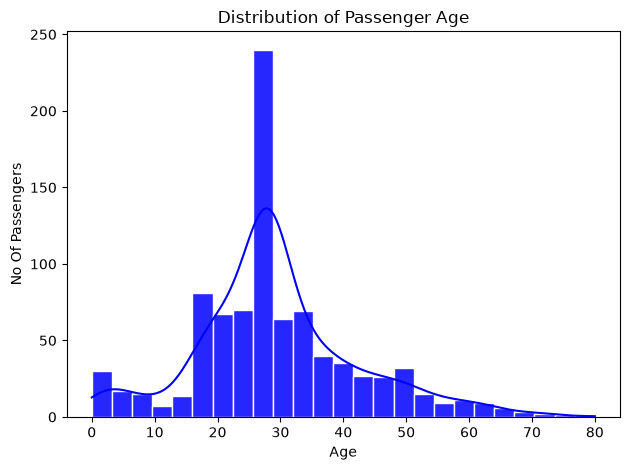

In [35]:
sns.histplot(data=df, x="Age", bins=25, kde=True, color="blue", edgecolor="White", alpha=0.85)
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("No Of Passengers")
plt.tight_layout()
plt.show()

##### Understand how ages are distributed and identify common age ranges

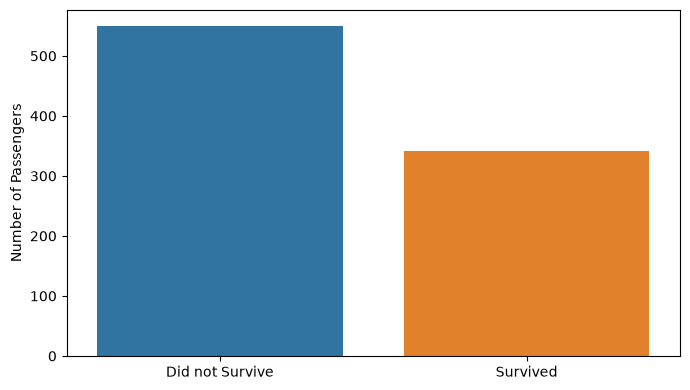

In [36]:
plt.figure(figsize=(7,4))
sns.countplot(data=df, x="Survived", hue="Survived", legend=False)
plt.xticks([0,1],["Did not Survive", "Survived"])
plt.title=("PassengerSurvival Counts")
plt.xlabel("")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

##### Compare the Number of passengers who survised and not survived

### Survival Rate By Gender

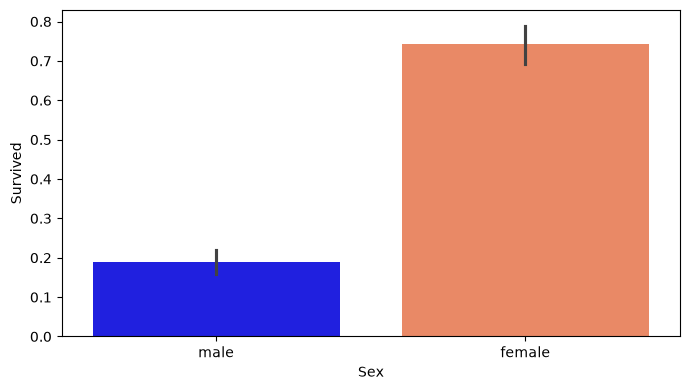

In [37]:
plt.figure(figsize=(7,4))
sns.barplot(data=df, x="Sex",y="Survived",
            hue="Sex", 
            palette={"male":"blue", "female": "coral"},
            legend= False)

plt.ylabel=("Survival Rate")
plt.tight_layout()
plt.show()


##### Examine the median age, the spread of the middle 50% of ages, and any potential outliers.

#### Age and outlier analysis
##### Age Distribution and Potential Outlier

In [41]:
sns.set_theme(style="whitegrid", context="notebook")

blue = "#3977A8"
teal = "#20A39E"
coral = "#F26B5B"
gold = "#E8B44F"
purple = "#8667AC"

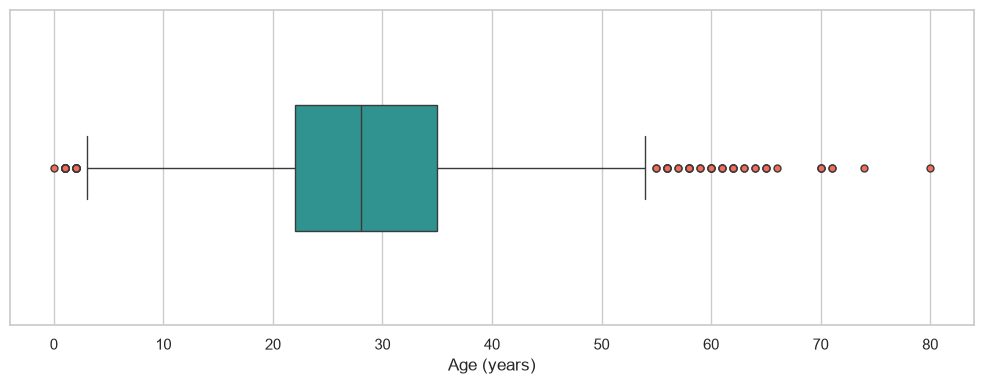

In [45]:

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df, x="Age",
    color=teal, width=0.4,
    flierprops={"marker": "o",
                "markerfacecolor": coral,
                "markersize": 5}
)

plt.xlabel("Age (years)")
plt.tight_layout()
plt.show()

##### Explore how fares vary by age and survival status. Look for clusters and unusual fares.

### Age vs. ticket fare

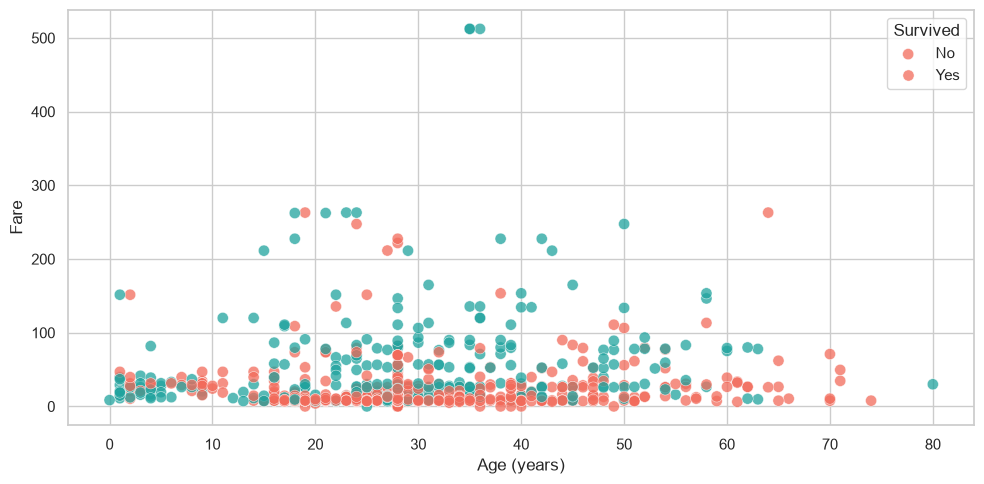

In [48]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df, x="Age", y="Fare",
    hue="Survived",
    palette={0: coral, 1: teal},
    alpha=0.75, s=65,
    edgecolor="white", linewidth=0.4
)

plt.xlabel("Age (years)")

plt.legend(title="Survived",
           labels=["No", "Yes"])
plt.tight_layout()
plt.show()

##### Explore how fares vary by age and survival status. Look for clusters and unusual fares.

##### Correlation heatmap
##### Correlation Between Numerical Features

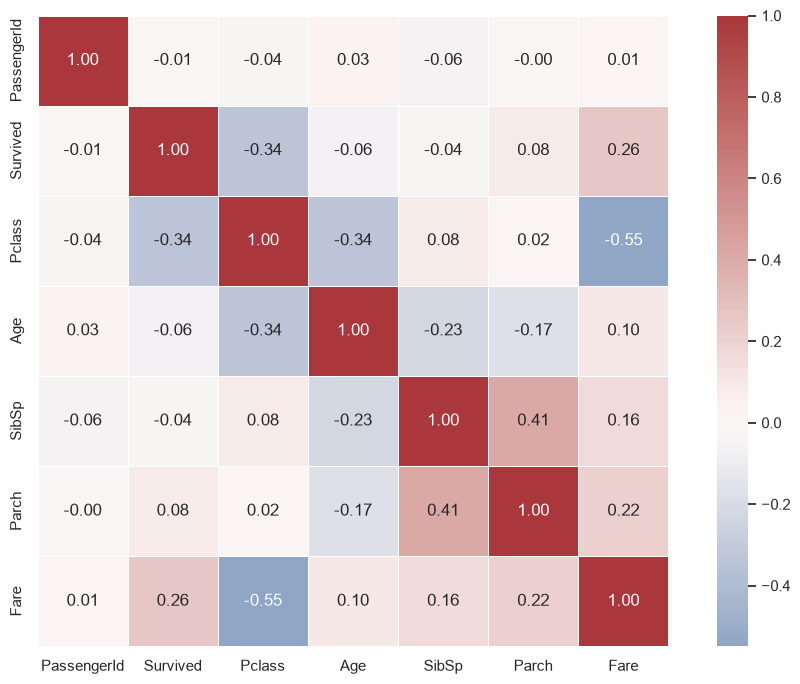

In [52]:

numeric = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric.corr(),
    annot=True, fmt=".2f",
    cmap="vlag", center=0,
    linewidths=0.6,
    square=True
)


plt.tight_layout()
plt.show()

##### Values close to +1 indicate strong positive linear correlation, values close to -1 indicate strong negative linear correlation, and values near 0 indicate weak linear correlation.

#### G. Survival rate by passenger class

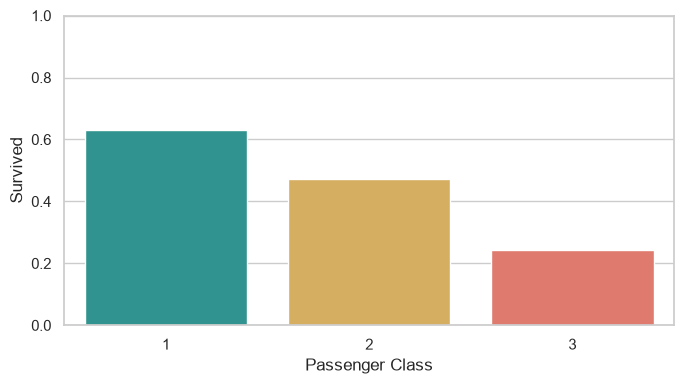

In [55]:
plt.figure(figsize=(7, 4))
sns.barplot(
    data=df, x="Pclass", y="Survived",
    hue="Pclass",
    estimator="mean",
    errorbar=None,
    palette={1: teal, 2: gold, 3: coral},
    legend=False
)

plt.xlabel("Passenger Class")

plt.ylim(0, 1)
plt.tight_layout()
plt.show()

##### Investigate whether survival proportions differed across ticket classes.

In [ ]:
#### Pairplot

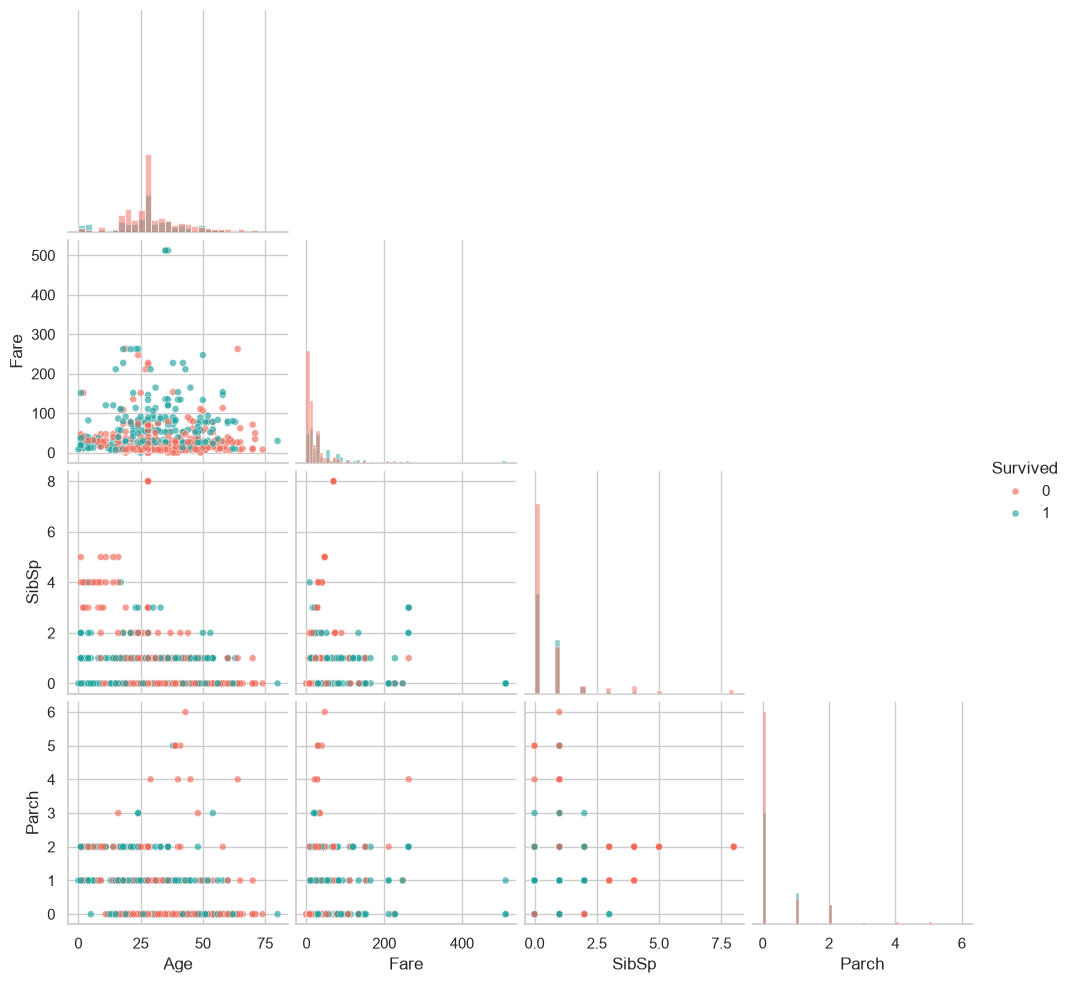

In [57]:
cols = ["Age", "Fare", "SibSp", "Parch", "Survived"]

sns.pairplot(
    df[cols].dropna(),
    hue="Survived",
    diag_kind="hist",
    palette={0: coral, 1: teal},
    corner=True,
    plot_kws={"alpha": 0.65, "s": 25}
)
plt.show()

##### Explore relationships among multiple numerical features, with points separated by survival status. Pairplots can be large, so this compact selection keeps the notebook easier to read.